In [96]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

In [97]:
data = pd.read_csv("noisy_curvefit_data.csv")

In [98]:
data.shape

(100, 6)

In [99]:
#100 rows, 6 columns

In [100]:
print(data.head(5), data.tail(5))

          x  y_noise_1  y_noise_2  y_noise_3  y_noise_4  y_noise_5
0 -1.000000  11.624419   8.296963  12.201067   7.811725   3.155566
1 -0.929293  10.377466   9.674440  12.198084   8.275006   7.518855
2 -0.858586  10.585100   9.251983  13.186565  12.926586   9.963630
3 -0.787879  10.913928   7.786344  12.552304  11.832379   9.625801
4 -0.717172   8.640287   8.551869   4.741432   8.790834   6.624113            x  y_noise_1  y_noise_2  y_noise_3  y_noise_4  y_noise_5
95  5.717172  -1.411918   0.822231  -2.027132  -1.825106   2.746147
96  5.787879   0.344879  -1.718956   2.747559  -6.803779  -5.137472
97  5.858586   0.307133   0.353528   0.967976   5.461567  -0.905616
98  5.929293   0.048657   0.159961   2.482130  -0.414616  -4.334548
99  6.000000  -0.193438  -2.244792   1.930035   4.992414  -6.872850


In [101]:
print(f"The column names are {str(list(data.columns))[1:-1]}") #slice the string because the list(data.columns) print []

The column names are 'x', 'y_noise_1', 'y_noise_2', 'y_noise_3', 'y_noise_4', 'y_noise_5'


Plot the x vs. y noise 1 column:

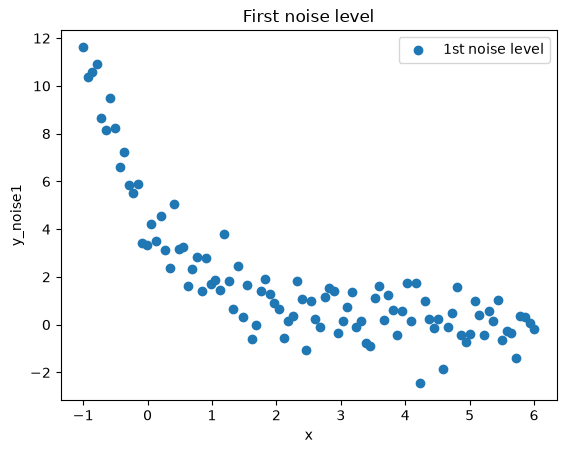

In [102]:
plt.figure()
plt.scatter(data["x"], data["y_noise_1"], label ="1st noise level")
plt.title("First noise level")
plt.xlabel("x")
plt.ylabel("y_noise1")
plt.legend()
plt.show()

In [103]:
def model(x, A, k):
    return A * np.exp(-k * x)

In [104]:
p0 = [1, 1]

In [105]:
popt, pcov = curve_fit(model, data["x"], data["y_noise_1"], p0=p0) 
#curve fit function takes our specified model and fits its parameters to the given data and overwrites our intial guess for the model parameters
#the output of curve_fit() are the estimated parameters and the varaiance-covaraince matrix of the parameters

In [106]:
A_fit, k_fit = popt

In [107]:
popt

array([4.71481388, 0.91830785])

In [108]:
A_fit

np.float64(4.714813878507004)

In [109]:
f"Fit: y = {A_fit:.2f} * e^(-{k_fit:.2f} * x)"

'Fit: y = 4.71 * e^(-0.92 * x)'

In [110]:
residuals = data["y_noise_1"] - model(data["x"], A_fit, k_fit)
chi2 = np.sum(residuals**2)
dof = len(data["x"]) - len(popt)
chi2_reduced = chi2 / dof

Plot the result:
• Scatter: noisy data
• Red line: fitted model
• Black dotted line: true model (use model(x, 5, 0.8))
Hint: Use linestyle="--" as an argument.
• Include the noise level (i.e., 1 since y noise 1) and reduced chi-squared in the title. Round
the reduced chi-squared to two decimal places.

• Add axis labels and a legend

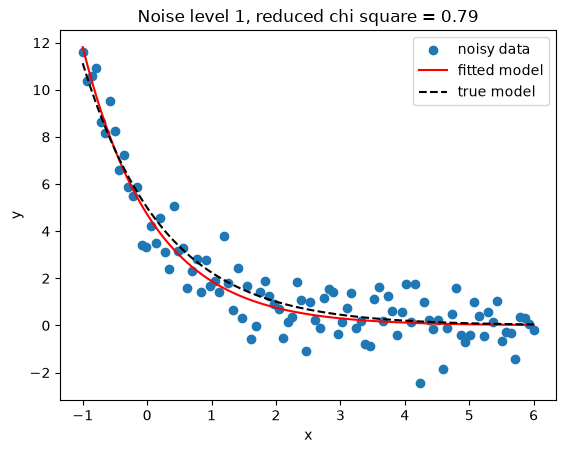

In [111]:
plt.figure()
plt.scatter(data["x"], data["y_noise_1"], label = "noisy data")
plt.plot(data["x"], model(data["x"], A_fit, k_fit), color= "red", label = "fitted model")
plt.plot(data["x"], model(data["x"], 5, 0.8), ls= "--", color="black", label = "true model")
plt.xlabel("x")
plt.ylabel("y")
plt.title(f"Noise level 1, reduced chi square = {chi2_reduced:.2f}")
plt.legend()
plt.show()

In [112]:
#2.3

In [113]:
def fit_model(x, y):
    popt, pcov = curve_fit(model, x, y, p0=p0)
    A_fit, k_fit = popt
    residuals = y - model(x, A_fit, k_fit)
    chi2 = np.sum(residuals**2)
    dof = len(x) - len(popt)
    chi2_reduced = chi2 / dof
    return popt, chi2_reduced



<Figure size 640x480 with 0 Axes>

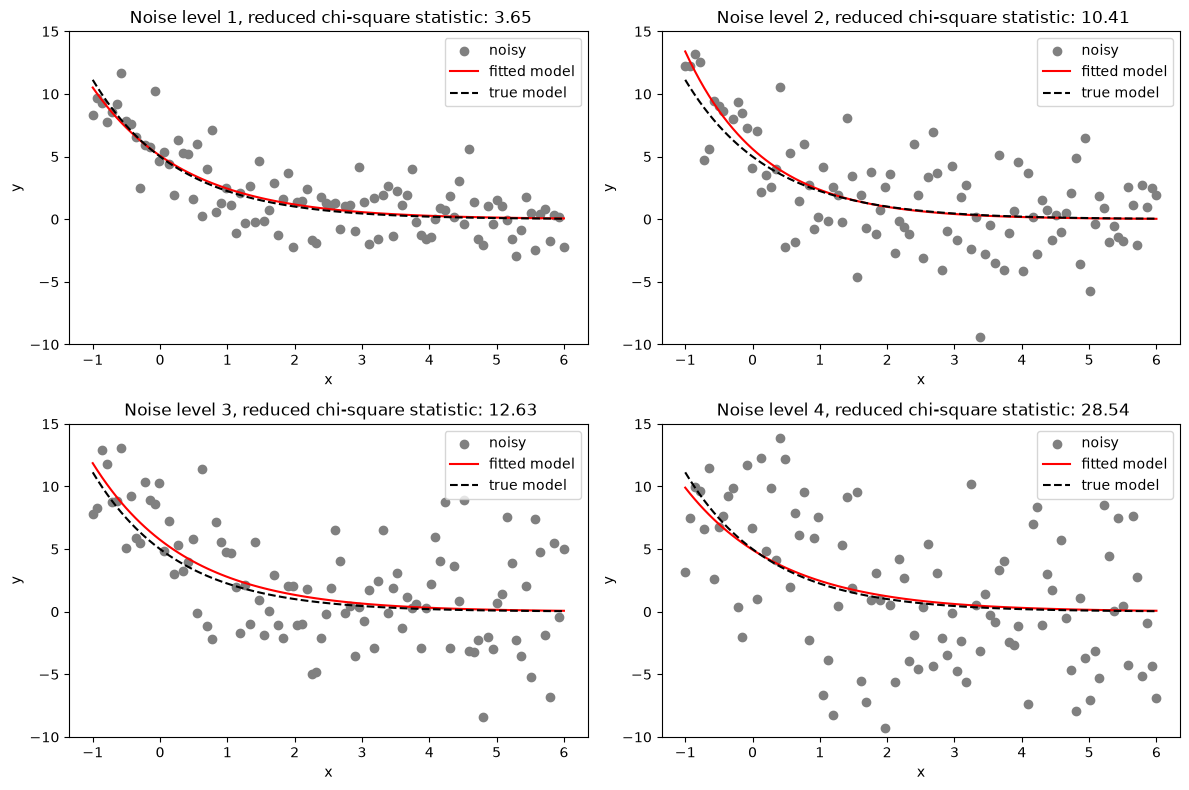

In [114]:
plt.figure()
fig, axes = plt.subplots(2,2, figsize = (12,8)) 
x = data["x"]
y_cols=["y_noise_2", 'y_noise_3', 'y_noise_4', 'y_noise_5']
for i, y in enumerate(y_cols):
    y_vals = data[y]
    row = i//2
    col = i%2
    fitted_params = fit_model(x,y_vals)[0]
    red_chisq = fit_model(x,y_vals)[1]
    axes[row,col].scatter(x,y_vals, color = "grey", label = "noisy")
    axes[row,col].plot(x, model(x, fitted_params[0], fitted_params[1]), color = "red", label = "fitted model")
    axes[row,col].plot(x, model(x, 5, 0.8), color = "black", ls = "--", label = "true model")
    axes[row,col].set_xlabel("x")
    axes[row,col].set_ylabel("y")
    axes[row,col].legend()
    axes[row,col].set_title(f" Noise level {i+1}, reduced chi-square statistic: {red_chisq:.2f}")
axes[0, 0].set_ylim(-10, 15)
axes[0, 1].set_ylim(-10, 15)
axes[1, 0].set_ylim(-10, 15)
axes[1, 1].set_ylim(-10, 15)
plt.tight_layout()
plt.show()



What happens to the red and black dotted lines as you increase the noise level?
Increasing the noise level leads to locally larger gaps between the red and black dotted line. The black dotted line remains the same, as it is unaffected by the noise. 
Why?
• What happens to the reduced chi-squared as you increase the noise level? Why? The chi-square increases with the noise level, simply because the spread of the data points from their non-noised value increases. Since the fitted line has to be on average correct, but the average deviation of a data point from the fitted model increases with noise, the chi-square statistics also increases.

In [131]:
results = {
    "noise level": [1,2,3,4,5],
    "A fit": [np.nan, np.nan, np.nan, np.nan, np.nan],
    "k fit": [np.nan, np.nan, np.nan, np.nan, np.nan],
    "Reduced chi square": [np.nan, np.nan, np.nan, np.nan,np.nan]
}

In [132]:
df = pd.DataFrame(results)

In [133]:
print(df)

   noise level  A fit  k fit  Reduced chi square
0            1    NaN    NaN                 NaN
1            2    NaN    NaN                 NaN
2            3    NaN    NaN                 NaN
3            4    NaN    NaN                 NaN
4            5    NaN    NaN                 NaN


In [134]:
y_cols=["y_noise_1","y_noise_2", 'y_noise_3', 'y_noise_4', 'y_noise_5']

for i, y_vals in enumerate (y_cols):
    y = data[y_vals]
    fit_model(x,y)
    best_param = fit_model(x,y)[0]
    chi_squ = fit_model(x,y)[1]
    df.iloc[i,1]=best_param[0]
    df.iloc[i,2]=best_param[1]
    df.iloc[i,3]=chi_squ
    

In [135]:
print(df)

   noise level     A fit     k fit  Reduced chi square
0            1  4.714814  0.918308            0.790673
1            2  5.063889  0.730396            3.649382
2            3  5.609396  0.870372           10.410207
3            4  5.738727  0.725965           12.626832
4            5  4.943458  0.695012           28.538124


In [139]:
df.to_csv("noisy_parameters.csv", index = False)